# Exploratory data analysis

In [51]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "Data" / "processed").is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError(f"Could not find Data/processed above {Path.cwd()}")
processed = root / "Data" / "processed"

tab = pd.read_parquet(processed / "table.parquet")
emb = pd.read_parquet(processed / "news_emb.parquet")
cnt = pd.read_parquet(processed / "news_count.parquet")["news_count"]

## 1. Structure

In [52]:
print(tab.shape)
print(tab.index.min(), tab.index.max())
print("Duplicate dates:", tab.index.duplicated().sum())
tab.dtypes

(5007, 15)
2005-02-02 00:00:00 2024-12-23 00:00:00
Duplicate dates: 0


Open           float64
High           float64
Low            float64
Close          float64
Volume           int64
log_ret        float64
rv_21          float64
log_volume     float64
hl_range       float64
cpi_yoy        float64
t10y2y         float64
fedfunds       float64
regime           int64
fwd_rv         float64
next_regime    float64
dtype: object

## 2. Missing values

Nothing is missing. **next_regime needs to be converted to integer**.

In [53]:
tab.isna().sum()

Open           0
High           0
Low            0
Close          0
Volume         0
log_ret        0
rv_21          0
log_volume     0
hl_range       0
cpi_yoy        0
t10y2y         0
fedfunds       0
regime         0
fwd_rv         0
next_regime    0
dtype: int64

## 3. Summary stats

In [54]:
tab.describe().T

,count,mean,std,min,25%,50%,75%,max
Open,5007.0,2.047001e+02,1.316354e+02,4.944108e+01,9.703474e+01,1.637976e+02,2.711525e+02,5.939825e+02
High,5007.0,2.058343e+02,1.322854e+02,5.093268e+01,9.762620e+01,1.646353e+02,2.720283e+02,5.953314e+02
Low,5007.0,2.034626e+02,1.309190e+02,4.882263e+01,9.630174e+01,1.628891e+02,2.701674e+02,5.933276e+02
Close,5007.0,2.047246e+02,1.316536e+02,4.955750e+01,9.707782e+01,1.636229e+02,2.711733e+02,5.940998e+02
Volume,5007.0,1.259822e+08,9.145718e+07,1.527000e+07,6.614655e+07,9.559900e+07,1.549465e+08,8.710263e+08
log_ret,5007.0,3.966616e-04,1.202472e-02,-1.158866e-01,-3.951274e-03,7.035062e-04,5.797655e-03,1.355773e-01
rv_21,5007.0,1.568041e-01,1.108203e-01,3.415856e-02,9.220336e-02,1.289475e-01,1.851193e-01,9.366844e-01
log_volume,5007.0,1.845748e+01,5.980056e-01,1.654140e+01,1.800738e+01,1.837567e+01,1.885859e+01,2.058518e+01
hl_range,5007.0,1.239979e-02,1.030389e-02,1.229285e-03,6.422179e-03,9.570396e-03,1.464688e-02,1.193259e-01
cpi_yoy,5007.0,2.585639e+00,1.936840e+00,-1.958761e+00,1.487589e+00,2.180565e+00,3.417918e+00,8.979361e+00


## 4. Targets

2008 to 2009, 2011, 2020 and 2022 carry the most regime 2 days, and 2008 and 2022 have no regime 0 days at all. 
The test period (2021 to 2024) has its crisis days occuring almost entirely in 2022, which limits how confident a test result on the crisis class can be.

regime
0    2231
1    2110
2     666
Name: count, dtype: int64
next_regime
0.0    2230
1.0    2111
2.0     666
Name: count, dtype: int64


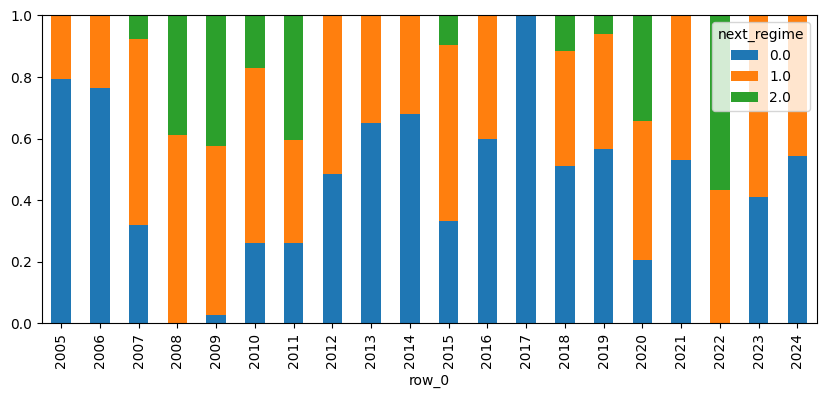

In [55]:
print(tab.regime.value_counts().sort_index())
print(tab.next_regime.value_counts().sort_index())
pd.crosstab(tab.index.year, tab.next_regime, normalize="index").plot.bar(stacked=True, figsize=(10, 4))
plt.show()

The raw fwd_rv is veery right-skewed, but the log version is close to a bell shape, centered around -2.2. So log(fwd_rv) should b used for modeling and converted back for reporting.

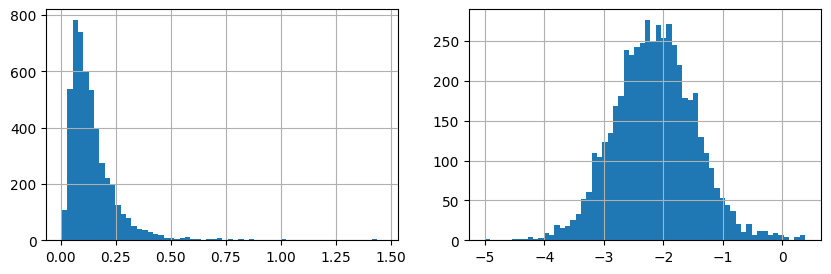

3.8975604659578726 0.13050868292866794
next_regime
0.0    0.083518
1.0    0.137717
2.0    0.274613
Name: fwd_rv, dtype: float64


In [56]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
tab.fwd_rv.hist(bins=60, ax=ax[0])
np.log(tab.fwd_rv).hist(bins=60, ax=ax[1])
plt.show()
print(tab.fwd_rv.skew(), np.log(tab.fwd_rv).skew())
print(tab.groupby("next_regime").fwd_rv.median())

## 5. Price and volume

Close trends from about 80 to about 590, so it’s a non-stationary level. Returns show volatility clustering around actual crash dates, while the largest up days are  next to the largest down days. rv_21 peaks at about 0.9 in both 2008 and 2020, but only about 0.3 in 2022.

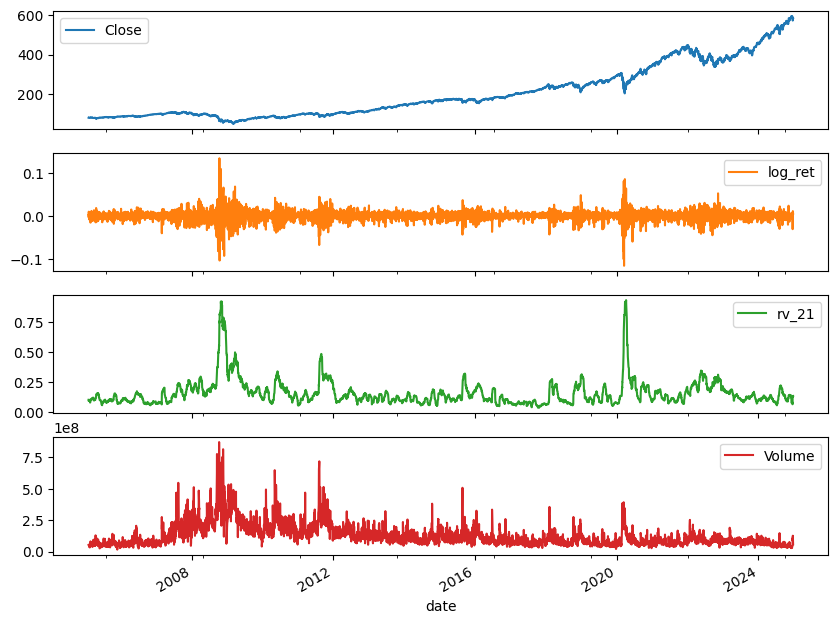

In [57]:
tab[["Close", "log_ret", "rv_21", "Volume"]].plot(subplots=True, figsize=(10, 8))
plt.show()

In [58]:
print(tab.log_ret.nsmallest(8))
print(tab.log_ret.nlargest(8))
print("excess kurtosis:", tab.log_ret.kurt())

date
2020-03-16   -0.115887
2008-10-15   -0.103637
2020-03-12   -0.100569
2008-12-01   -0.092749
2008-09-29   -0.081603
2020-03-09   -0.081313
2008-11-20   -0.077133
2008-10-09   -0.072397
Name: log_ret, dtype: float64
date
2008-10-13    0.135577
2008-10-28    0.110517
2020-03-24    0.086731
2020-03-13    0.082028
2009-03-23    0.069366
2008-11-24    0.066996
2020-04-06    0.065007
2008-11-13    0.060474
Name: log_ret, dtype: float64
excess kurtosis: 14.372892759617502


## 6. Macro features

CPI and fed funds move in steps, and the spread moves daily. All three track history correctly.

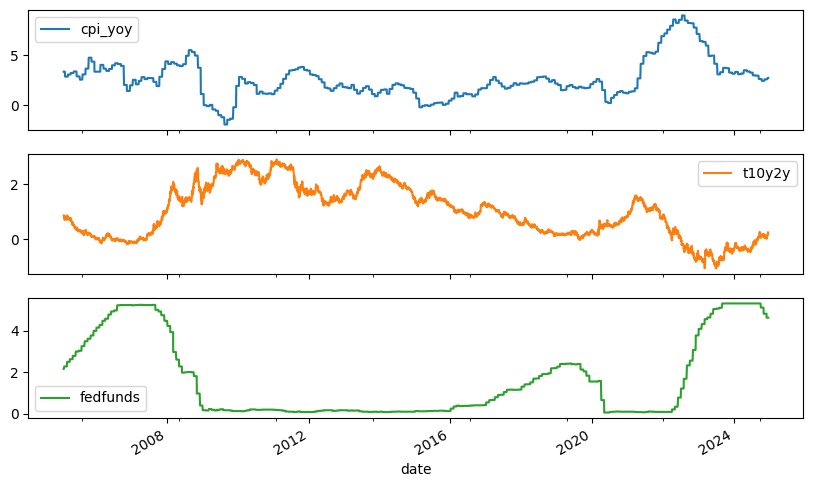

In [59]:
tab[["cpi_yoy", "t10y2y", "fedfunds"]].plot(subplots=True, figsize=(10, 6))
plt.show()

## 7. Correlations

Open/High/Low/Close are all 1.00 with each other, and Volume/log_volume are 1.00. Price level correlates -0.54 with the spread and -0.49 with volume. regime correlates 0.91 with rv_21, so the labels are mostly a version of trailing volatility. regime vs next_regime is 0.97, so “tomorrow equals today” will be a very strong baseline. log_ret vs fwd_rv is -0.13, so falling prices tend to precede higher vol. Correlations with the targets are weak, and the macro columns are collinear with each other. Because they move so slowly, they may invite memorizing periods.

In [60]:
tab.corr(method="spearman").round(2)

,Open,High,Low,Close,Volume,log_ret,rv_21,log_volume,hl_range,cpi_yoy,t10y2y,fedfunds,regime,fwd_rv,next_regime
Open,1.00,1.00,1.00,1.00,-0.49,0.01,-0.13,-0.49,-0.19,0.19,-0.54,0.07,-0.12,-0.12,-0.12
High,1.00,1.00,1.00,1.00,-0.49,0.01,-0.13,-0.49,-0.18,0.19,-0.54,0.07,-0.12,-0.12,-0.12
Low,1.00,1.00,1.00,1.00,-0.50,0.01,-0.13,-0.50,-0.19,0.19,-0.54,0.07,-0.13,-0.12,-0.13
Close,1.00,1.00,1.00,1.00,-0.49,0.02,-0.13,-0.49,-0.19,0.19,-0.54,0.07,-0.12,-0.12,-0.12
Volume,-0.49,-0.49,-0.50,-0.49,1.00,-0.10,0.52,1.00,0.67,-0.14,0.56,-0.27,0.50,0.46,0.51
log_ret,0.01,0.01,0.01,0.02,-0.10,1.00,0.01,-0.10,-0.09,-0.03,0.00,-0.02,-0.00,-0.13,-0.01
rv_21,-0.13,-0.13,-0.13,-0.13,0.52,0.01,1.00,0.52,0.64,0.07,0.13,-0.11,0.91,0.56,0.90
log_volume,-0.49,-0.49,-0.50,-0.49,1.00,-0.10,0.52,1.00,0.67,-0.14,0.56,-0.27,0.50,0.46,0.51
hl_range,-0.19,-0.18,-0.19,-0.19,0.67,-0.09,0.64,0.67,1.00,0.11,0.10,-0.04,0.60,0.57,0.61
cpi_yoy,0.19,0.19,0.19,0.19,-0.14,-0.03,0.07,-0.14,0.11,1.00,-0.45,0.39,0.08,0.10,0.08


The regime changes on only 113 of 5007 days (2.3%), so predicting “same as today” is right 97.7% of the time. Transitions go only through the middle state, with no direct jumps between calm and crisis. Entries into crisis happen only 13 times in the whole sample.

In [61]:
cols = ["cpi_yoy", "t10y2y", "fedfunds"]
tr, te = tab[tab.index <= "2017-12-31"], tab[tab.index > "2020-12-31"]
pd.concat({"train": tr[cols].agg(["min", "max"]), "test": te[cols].agg(["min", "max"])})

rel_vol = tab.log_volume - tab.log_volume.rolling(252, min_periods=60).mean()
print(rel_vol.corr(tab.fwd_rv, method="spearman"), tab.log_volume.corr(tab.fwd_rv, method="spearman"))

print((tab.regime == tab.next_regime).mean(), (tab.regime != tab.next_regime).sum())
print(pd.crosstab(tab.regime, tab.next_regime))

0.36809863298439954 0.4620368939094315
0.9774315957659278 113
next_regime   0.0   1.0  2.0
regime                      
0            2187    44    0
1              43  2054   13
2               0    13  653


## 8. Train, val, test periods

Each class appears in each period, with crisis at 12%, 17% and 14%. The class mix differs between periods, so a model’s scores aren’t directly comparable across them without looking at each class separately.

In [62]:
split = np.select([tab.index <= "2017-12-31", tab.index <= "2020-12-31"], ["train", "val"], "test")
print(pd.crosstab(split, tab.next_regime))
print(pd.crosstab(split, tab.next_regime, normalize="index").round(3))

next_regime   0.0   1.0  2.0
row_0                       
test          371   487  142
train        1536  1322  393
val           323   302  131
next_regime    0.0    1.0    2.0
row_0                           
test         0.371  0.487  0.142
train        0.472  0.407  0.121
val          0.427  0.399  0.173


## 9. News files

In [63]:
print(emb.shape, cnt.shape)
print(emb.index.min(), emb.index.max())
print(cnt.index.min(), cnt.index.max())
print("Duplicates emb:", emb.index.duplicated().sum())
print("Duplicates cnt:", cnt.index.duplicated().sum())
emb.dtypes
emb.isna().sum()
cnt.dtypes
cnt.isna().sum()

(3645, 771) (3645,)
2009-04-29 00:00:00 2024-01-09 00:00:00
2009-04-29 00:00:00 2024-01-09 00:00:00
Duplicates emb: 0
Duplicates cnt: 0


np.int64(0)

### 9a. news_count

The covered window with news is roughly 2010-2023. 

count    3645.000000
mean       65.110562
std        35.725653
min         1.000000
25%        50.000000
50%        50.000000
75%        50.000000
max       200.000000
Name: news_count, dtype: float64


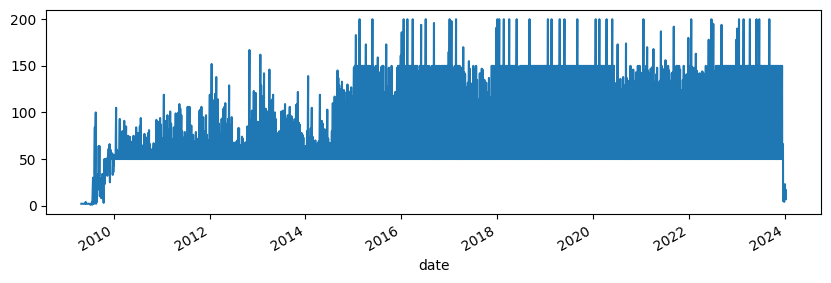

In [64]:
print(cnt.describe())
cnt.plot(figsize=(10, 3))
plt.show()

Mean daily article count is the same across regimes. 

In [65]:
has_news = tab.index.isin(emb.index)
n = cnt.reindex(tab.index)
print(n[has_news].groupby(tab.next_regime[has_news]).mean())
print("Spearman:", n[has_news].corr(tab.fwd_rv[has_news], method="spearman"))

next_regime
0.0    65.805707
1.0    64.125725
2.0    65.966443
Name: news_count, dtype: float64
Spearman: -0.012368483904485552


### 9b. news_emb

In [66]:
print("NaNs:", emb.isna().sum().sum(), "| all-zero rows:", (emb.abs().sum(axis=1) == 0).sum())
print(emb.std().describe())

NaNs: 0 | all-zero rows: 0
count    771.000000
mean       0.136187
std        0.045680
min        0.061137
25%        0.103062
50%        0.126376
75%        0.160794
max        0.363449
dtype: float64


In [ ]:
norms = pd.Series(np.linalg.norm(emb.values, axis=1), index=emb.index)
print(norms.describe())
print("Spearman(norm, article count):", norms.corr(cnt.reindex(emb.index), method="spearman"))

count    3645.000000
mean       10.404316
std         0.860875
min         8.461560
25%         9.855553
50%        10.261426
75%        10.803357
max        17.153885
dtype: float64
Spearman(norm, article count): 0.1435146389977425


In [ ]:
X = emb.values
rng = np.random.default_rng(0)
i, j = rng.integers(0, len(X), 2000), rng.integers(0, len(X), 2000)
cos = (X[i] * X[j]).sum(1) / (np.linalg.norm(X[i], axis=1) * np.linalg.norm(X[j], axis=1))
print("mean cosine similarity between random days:", cos.mean())

mean cosine similarity between random days: 0.8610861


## 10. Summary


- The main table has 5,007 trading days (2005-02-02 to 2024-12-23) and 15 columns, with no duplicate dates, no calendar gaps and no missing values. The first and last years are short (231 rows in 2005, 247 in 2024). 
`next_regime` is stored as float and should be cast to int.

- Next-day regime is 44.6% calm, 42.1% middle and 13.3% crisis and median forward volatility rises with the regime (0.084, 0.138, 0.275).
- The regime is extremely persistent, because it changes on 113 of 5,007 days (2.3%), so predicting "same as today" is correct 97.7% of the time. Changes only happen between adjacent states with no direct calm-to-crisis jumps. The market moves from middle to crisis only 13 times in 20 years. Accuracy doesn't seem to be a usable metric.
- `fwd_rv` is right-skewed and close to symmetric in logs, so the regression target should be log volatility.
- Open, High, Low and Close trend from about 80 to about 590 and are perfectly correlated with each othe, so they are redundant.
- `regime` correlates 0.91 with `rv_21`, so the labels are a bucketed trailing volatility. `hl_range` (0.57) is about as correlated with `fwd_rv` as `rv_21` (0.56).
- The three macro features change in steps and are only weakly correlated with the targets (0.06 to 0.11). The problem is that test-period ranges are different compaed to training ranges.
- News exists from 2009-04-29 to 2024-01-09. 
- `news_count` has the median of 50, a floor at 50 and ceilings near 150 and 200, which looks like a sampling cap. 
- Every class appears in every period, but crisis days come in long runs, which makes it look like the test crisis is the single 2022 episode.


### Cleaning decisions
- `next_regime` stored as float - cast to int 
- Open, High, Low, Close levels and `Volume` are redundant
- Volume trend - use relative volume
- Skewed volatility target - model log `fwd_rv` 
- Fed funds near zero
- `regime` nearly equals `rv_21`
- News missing before 2009 and in 2024 
- 97.7% persistence